# 31 · The geometric Jacobian: derivation, MuJoCo's `mj_jacSite`, singularities

In [1]:
import mujoco, mujoco_menagerie as mm, numpy as np, matplotlib.pyplot as plt
from vlacourse import add_ee_site

def panda():
    spec = mm.get("franka_emika_panda").spec("panda")
    add_ee_site(spec)
    m = spec.compile()
    return m, mujoco.MjData(m)

def geometric_jacobian(model, data, site="ee"):
    """J_v[:, i] = z_i x (p_ee - p_i),  J_w[:, i] = z_i  for revolute joints."""
    p_ee = data.site(site).xpos
    J = np.zeros((6, 7))
    for i in range(7):
        j = model.joint(f"joint{i + 1}")
        z = data.xaxis[j.id]
        p = data.xanchor[j.id]
        J[:3, i] = np.cross(z, p_ee - p)
        J[3:, i] = z
    return J

def mj_jacobian(model, data, site="ee"):
    jp, jr = np.zeros((3, model.nv)), np.zeros((3, model.nv))
    mujoco.mj_jacSite(model, data, jp, jr, model.site(site).id)
    return np.vstack([jp, jr])[:, :7]

def set_q(model, data, q):
    data.qpos[:7] = q
    mujoco.mj_kinematics(model, data); mujoco.mj_comPos(model, data)

In [2]:
model, data = panda()
rng = np.random.default_rng(0)
for _ in range(3):
    set_q(model, data, rng.uniform(model.jnt_range[:7, 0], model.jnt_range[:7, 1]))
    print("max |J_ours - mj_jacSite| =", np.abs(geometric_jacobian(model, data) - mj_jacobian(model, data)).max())

max |J_ours - mj_jacSite| = 5.551115123125783e-17
max |J_ours - mj_jacSite| = 5.551115123125783e-17
max |J_ours - mj_jacSite| = 5.551115123125783e-17


In [3]:
q = np.array([0, 0.3, 0, -1.6, 0, 1.9, 0.785])
set_q(model, data, q)
J = mj_jacobian(model, data)
dq = rng.normal(0, 0.01, 7)
x0 = data.site("ee").xpos.copy()
set_q(model, data, q + dq)
print("predicted dx = J dq :", (J[:3] @ dq).round(5))
print("actual    dx        :", (data.site("ee").xpos - x0).round(5))

predicted dx = J dq : [0.00061 0.01121 0.00799]
actual    dx        : [0.00046 0.01121 0.008  ]


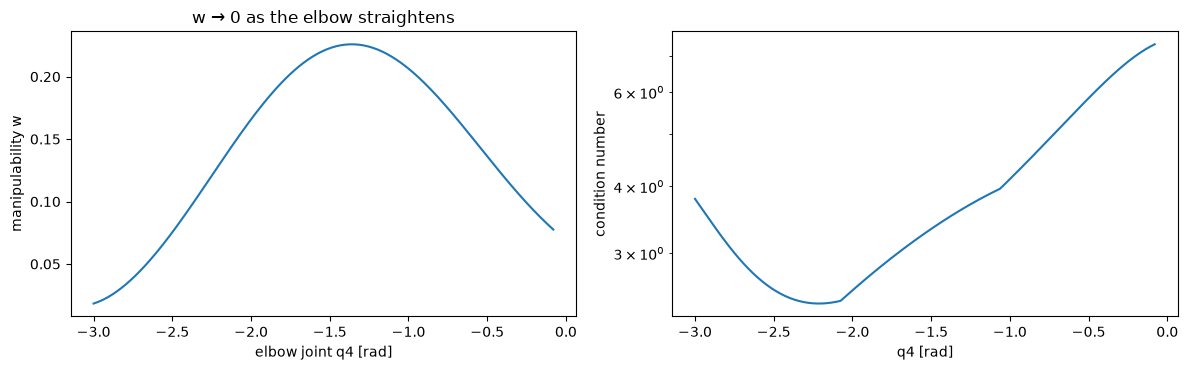

In [4]:
q4s = np.linspace(-3.0, -0.08, 200)
w, cond = [], []
for q4 in q4s:
    q = np.array([0, 0.3, 0, q4, 0, 1.9, 0.785]); set_q(model, data, q)
    s = np.linalg.svd(mj_jacobian(model, data)[:3], compute_uv=False)
    w.append(np.prod(s)); cond.append(s[0] / s[-1])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(q4s, w); ax[0].set_xlabel("elbow joint q4 [rad]"); ax[0].set_ylabel("manipulability w"); ax[0].set_title("w → 0 as the elbow straightens")
ax[1].semilogy(q4s, cond); ax[1].set_xlabel("q4 [rad]"); ax[1].set_ylabel("condition number"); plt.tight_layout(); plt.show()

In [5]:
v_des = np.array([0.1, 0, 0, 0, 0, 0])
rows = []
for q4 in [-1.6, -0.5, -0.15, -0.08]:
    set_q(model, data, np.array([0, 0.3, 0, q4, 0, 1.9, 0.785]))
    J = mj_jacobian(model, data)
    dq_pinv = np.linalg.pinv(J) @ v_des
    dq_dls = J.T @ np.linalg.solve(J @ J.T + 1e-2 * np.eye(6), v_des)
    rows.append((q4, np.abs(dq_pinv).max(), np.abs(dq_dls).max(), np.linalg.norm(J @ dq_dls - v_des)))
print(" q4     |dq| pinv   |dq| DLS(λ=0.1)   DLS velocity error")
for r in rows:
    print(f"{r[0]:6.2f} {r[1]:10.3f} {r[2]:12.3f} {r[3]:14.4f}")

 q4     |dq| pinv   |dq| DLS(λ=0.1)   DLS velocity error
 -1.60      0.484        0.336         0.0278
 -0.50      9.220        0.122         0.0532
 -0.15      0.663        0.183         0.0304
 -0.08      0.492        0.186         0.0253
